In [14]:
import rebound
import reboundx
import numpy as np
import matplotlib.pyplot as plt

In [15]:
sim = rebound.Simulation()
sim.integrator = "ias15"
sim.units = ("AU", "yr", "Msun")

In [22]:
M0 = 0.8645388227818771
R0 = 0.3833838293200158

sim.add(m=M0, r=R0)
sim.add(m=1e-3, a=5.2, e=0, r=0.0000477895)
sim.add(m=3e-4, a=6.7, e=0, r=0.0000403)
sim.move_to_com()

In [17]:
data = np.loadtxt("m.txt")
mtimes = data[:, 0]
masses = data[:, 1]

data = np.loadtxt("r.txt")
rtimes = data[:, 0]
Rsuns = data[:, 1]      # data ins Rsun units

# Convert Rsun to AU
radii = np.zeros(Rsuns.size)
for i, r in enumerate(Rsuns):
    radii[i] = r * 0.00465047

In [18]:
rebx = reboundx.Extras(sim)
starmass = reboundx.Interpolator(rebx, mtimes, masses, "spline")
starradius = reboundx.Interpolator(rebx, rtimes, masses, "spline") 


In [19]:
sim.integrate(0.0)
sim.widget(size=(950,950))

REBOUND Webserver listening on http://localhost:1234 (not secure) ...


In [20]:
a1 = []
e1 = []
t1 = []
a2 = []
e2 = []
t2 = []
m_star = []
r_star = []

E0 = sim.energy()
Lx0, Ly0, Lz0 = sim.angular_momentum()
L0 = np.sqrt(Lx0**2 + Ly0**2 + Lz0**2)

err_ener=[]
err_ang=[]

tmax = 4.e6
Num = 100000
times = np.linspace(0, tmax, Num)
T0 = 1.23895e10 # Age of the sun at the start of the simulation

for i, time in enumerate(times):
    sim.integrate(time)
    sim.particles[0].m = starmass.interpolate(rebx, t=T0+sim.t)
    sim.particles[0].r = starradius.interpolate(rebx, t=T0+sim.t)
    sim.move_to_com()
    
    if sim.N > 1:
        a1.append(sim.particles[1].a)
        e1.append(sim.particles[1].e)
        t1.append(times[i])
    if sim.N > 2:
        a2.append(sim.particles[2].a)
        e2.append(sim.particles[2].e)
        t2.append(times[i])

    E_actual = sim.energy()
    err_ener.append(abs((E_actual - E0) / E0))

    Lx, Ly, Lz = sim.angular_momentum()
    L_actual = np.sqrt(Lx**2 + Ly**2 + Lz**2)
    err_ang.append(abs((L_actual - L0) / L0))

    m_star.append(sim.particles[0].m)
    r_star.append(sim.particles[0].r)


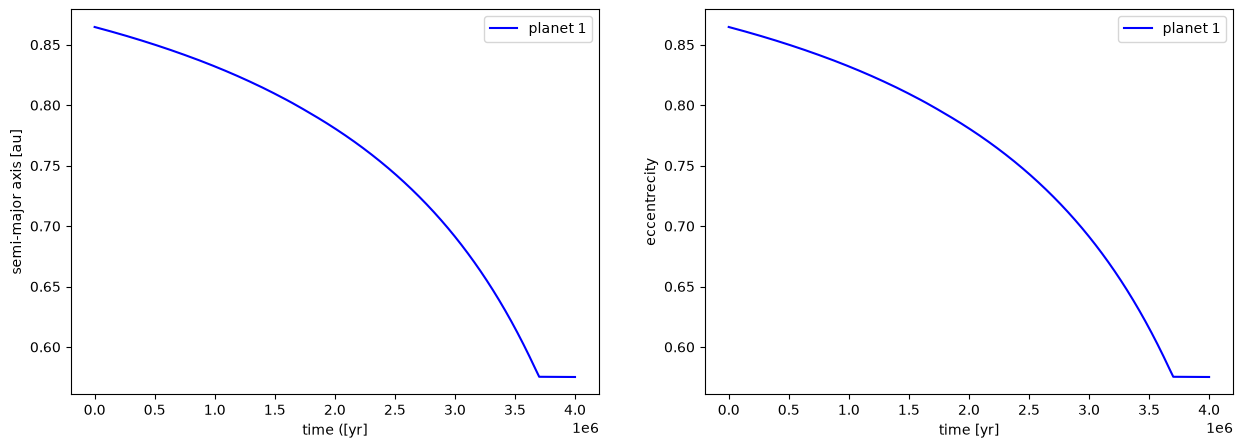

In [9]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time ([yr]")
ax.set_ylabel("semi-major axis [au]")
# ax.set_ylabel("err_ener")
plt.plot(times, m_star, color="blue", label="planet 1")
# plt.plot(t1, err_ener, color="blue", label="planet 1")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time [yr]")
ax.set_ylabel("eccentrecity")
# ax.set_ylabel("err_ang")
plt.plot(times, r_star, color="blue", label="planet 1")
# plt.plot(t1, err_ang, color="blue", label="planet 1")
ax.legend(loc="best")

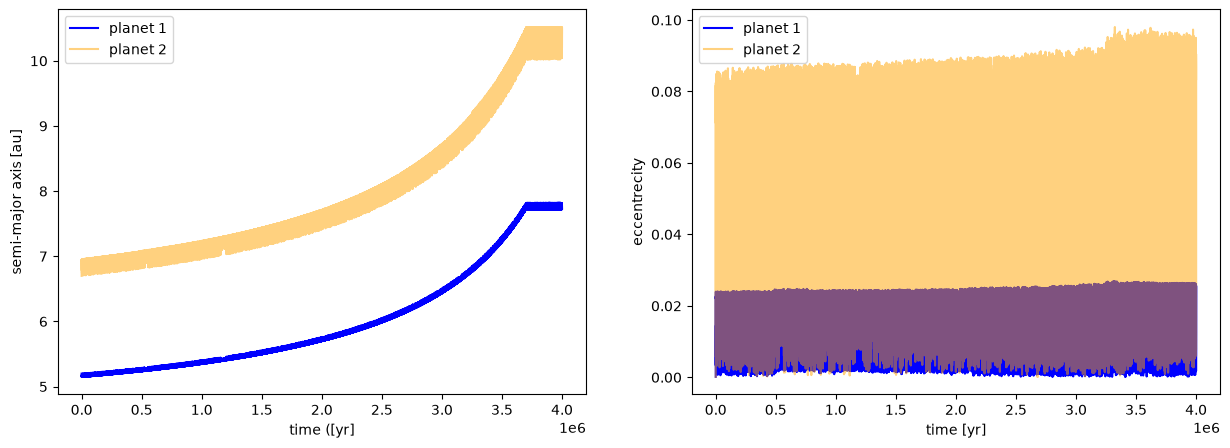

In [21]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time ([yr]")
ax.set_ylabel("semi-major axis [au]")
# ax.set_ylabel("err_ener")
plt.plot(t1, a1, color="blue", label="planet 1")
plt.plot(t2, a2, color="orange", alpha=0.5, label="planet 2")
# plt.plot(t1, err_ener, color="blue", label="planet 1")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time [yr]")
ax.set_ylabel("eccentrecity")
# ax.set_ylabel("err_ang")
plt.plot(t1, e1, color="blue", label="planet 1")
plt.plot(t2, e2, color="orange", alpha=0.5, label="planet 2")
# plt.plot(t1, err_ang, color="blue", label="planet 1")
ax.legend(loc="best")

/tmp/ipykernel_20290/3955692140.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="best")
/tmp/ipykernel_20290/3955692140.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="best")


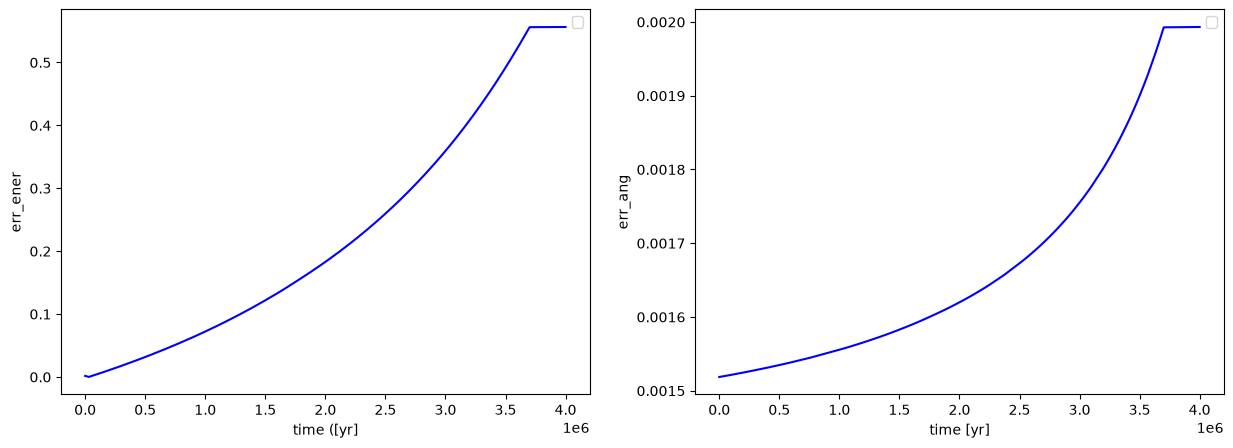

In [11]:
fig = plt.figure(figsize=(15,5))

ax = plt.subplot(121)
ax.set_xlabel("time ([yr]")
ax.set_ylabel("err_ener")
plt.plot(t1, err_ener, color="blue")
ax.legend(loc="best")

ax = plt.subplot(122)
ax.set_xlabel("time [yr]")
ax.set_ylabel("err_ang")
plt.plot(t1, err_ang, color="blue")
ax.legend(loc="best")

In [12]:
ww

NameError: name 'ww' is not defined